<div align="center">

<h1> <b> PÉNDULO MAGNÉTICO: DINÁMICA NO LINEAL Y COMPORTAMIENTO CAÓTICO </b> </h1>

</div>

<br>

<hr size=10 noshade color="green">
<p>
<p><img alt="UdeA logo" height="180px" src="https://upload.wikimedia.org/wikipedia/commons/archive/f/fb/20161010213812%21Escudo-UdeA.svg" align="left" hspace="100px" vspace="4px"></p>

<div align="right">       

<h3><i> <b>Cristian Vergara Restrepo <br>
Bernardo Mendoza Montes</b> <br>  
Universidad de Antioquia <br>
Instituto de Física  
</i></h3>
</div>

---

## Planteamiento del problema

El péndulo magnético combina una restricción geométrica sencilla (un péndulo de longitud fija que oscila bajo la gravedad) con fuerzas no lineales debidas a imanes fijos situados sobre un plano horizontal, justo por debajo del punto más bajo de la trayectoria de la masa. Pese a la sencillez de su formulación, el sistema exhibe una dinámica rica: pequeños cambios en las condiciones iniciales pueden conducir a trayectorias completamente distintas.

En este trabajo se estudia un péndulo de masa puntual, suspendido de un pivote fijo, sometido a tres fuerzas:

- la gravedad,
- una fricción viscosa proporcional a la velocidad,
- y la atracción de tres imanes fijos.

Como la fricción disipa energía, el péndulo termina siempre en reposo junto a uno de los imanes. Lo difícil de anticipar es junto a cuál: el sistema es completamente determinista, pero el imán de captura depende de manera muy sensible de la posición de partida, y las regiones de condiciones iniciales que conducen a cada imán (sus cuencas de atracción) están separadas por fronteras de estructura muy intrincada. Por eso el péndulo magnético es uno de los ejemplos más citados de caos en sistemas disipativos: el movimiento irregular es transitorio, porque termina en un punto de equilibrio, pero el estado final es prácticamente impredecible sin simular el sistema (Motter et al., 2013).

## Objetivos

### Objetivo general

Modelar numéricamente la dinámica de un péndulo magnético tridimensional y caracterizar la sensibilidad de su estado final a las condiciones iniciales.

### Objetivos específicos

- Formular las ecuaciones de movimiento del péndulo incluyendo las fuerzas gravitatoria, disipativa y magnética.
- Implementar un método de integración temporal que respete la restricción geométrica del sistema (longitud constante del péndulo).
- Visualizar la trayectoria proyectada del péndulo sobre el plano horizontal y el paisaje de energía potencial que la gobierna.
- Construir el mapa de cuencas de atracción de los imanes y cuantificar la sensibilidad del imán de captura frente a perturbaciones de la condición inicial.

# Metodología y modelo físico

## Descripción del sistema físico

El sistema consiste en una masa puntual $m$ unida a un pivote fijo mediante una cuerda inextensible de longitud $L$. Los imanes están en el plano horizontal $z = 0$ y el pivote se ubica a una altura $H = L + d$ sobre ese plano, de modo que, en su punto más bajo, la masa pasa a una distancia $d$ por encima de los imanes.

La posición de la masa se describe en coordenadas cartesianas tridimensionales, pero su movimiento está restringido a la superficie de una esfera de radio $L$ centrada en el pivote. Como la masa permanece siempre cerca del fondo de esa esfera, su posición queda determinada por la proyección horizontal $(x, y)$, y todas las figuras se presentan en ese plano.

## Fuerzas consideradas

### Fuerza gravitacional

La fuerza gravitacional actúa verticalmente hacia abajo:

$$
\mathbf{F}_g = (0,\,0,\,-mg)
$$

### Fuerza de fricción viscosa

Se modela como una fuerza disipativa proporcional a la velocidad de la masa:

$$
\mathbf{F}_f = -b\,\mathbf{v}
$$

con $b$ el coeficiente de fricción viscosa.

### Fuerza magnética

Cada imán se modela como una fuente puntual que atrae a la masa con una fuerza cuya intensidad decae con el cuadrado de la distancia:

$$
\mathbf{F}_{\text{mag}} = -K\,\frac{\mathbf{r}}{|\mathbf{r}|^3}
$$

donde $\mathbf{r}$ es el vector que va del imán a la masa y $K > 0$ caracteriza la intensidad del imán. La magnitud de la fuerza es $K/|\mathbf{r}|^2$ y su dirección apunta de la masa hacia el imán. Esta ley de fuerza es la idealización habitual en los modelos de este sistema; la interacción entre dos imanes permanentes reales es la de dos dipolos, que decae más rápido con la distancia. La fuerza magnética total es la suma de las contribuciones de los tres imanes (principio de superposición).

### Energía potencial

La gravedad y la atracción de los imanes son fuerzas conservativas, que derivan de la energía potencial

$$
U(\mathbf{r}) = m g z - \sum_{k=1}^{3} \frac{K}{|\mathbf{r} - \mathbf{r}_k|},
$$

donde $\mathbf{r}_k$ es la posición del imán $k$. Evaluada sobre la esfera a la que está restringida la masa, $U$ determina las posiciones de equilibrio del péndulo: sus mínimos son los puntos donde la masa puede quedar en reposo, y la fricción hace que toda trayectoria termine en uno de ellos.

## Restricción geométrica

Como la cuerda no se estira, la masa del péndulo está obligada a moverse sobre una esfera de radio $L$ centrada en el pivote. Para que esta restricción se respete durante la integración numérica, en cada paso de tiempo se procede así:

1. Se calcula la aceleración a partir de la fuerza total.
2. Se descarta la componente radial de esa aceleración, dejando solo la componente tangencial a la esfera.
3. Se corrige la velocidad, eliminando cualquier componente radial que pudiera haber quedado.
4. Se reescala el vector de posición para que su longitud vuelva a ser exactamente $L$.

Este último paso es clave: sin él, los errores de truncamiento y de redondeo se irían acumulando paso a paso y, tras suficientes iteraciones, la masa terminaría "flotando" fuera de la esfera permitida. La tensión de la cuerda no se calcula explícitamente: su efecto es precisamente mantener la masa sobre la esfera, y eso es lo que imponen los pasos 2 a 4.

## Integración temporal

La evolución temporal se calcula con el método de Euler-Cromer (Cromer, 1981), una pequeña modificación del método de Euler explícito que mejora notablemente su estabilidad en sistemas oscilatorios:

$$
\mathbf{v}_{n+1} = \mathbf{v}_n + \mathbf{a}_n \,\Delta t
$$

$$
\mathbf{r}_{n+1} = \mathbf{r}_n + \mathbf{v}_{n+1} \,\Delta t
$$

La diferencia con el Euler explícito estándar es sutil pero importante: la posición se actualiza usando la velocidad *nueva* ($\mathbf{v}_{n+1}$) en vez de la velocidad del paso anterior. Esto evita que la energía del sistema crezca artificialmente con el tiempo, un problema típico del Euler explícito en osciladores. Aunque sigue siendo un método de primer orden, resulta suficiente para el estudio cualitativo y estadístico de un sistema disipativo como este, siempre que el paso de tiempo sea pequeño frente a la escala temporal más rápida del movimiento. Esa escala la fija el paso de la masa sobre un imán, donde la fuerza magnética cambia apreciablemente en distancias del orden de $d$; por eso se usa $\Delta t = 2$ ms, y más adelante se comprueba que el mapa de cuencas de atracción prácticamente no cambia al reducir el paso a la mitad.

## Implementación computacional

El integrador avanza simultáneamente un conjunto arbitrario de trayectorias: las posiciones y velocidades se almacenan en arreglos de NumPy (Harris et al., 2020) y cada paso de tiempo actualiza todos sus elementos con operaciones vectorizadas. Así, la misma función sirve para seguir una trayectoria individual y para barrer decenas de miles de condiciones iniciales, como exige el mapa de cuencas de atracción: el costo del intérprete de Python se paga una vez por paso de tiempo y no una vez por trayectoria.

Una trayectoria se da por capturada cuando la masa se encuentra, en proyección horizontal, a menos de $r_{\text{cap}}$ de un imán y con una rapidez menor que $v_{\text{cap}}$. Desde ese momento deja de integrarse, lo que reduce el costo de los barridos sin cambiar el resultado: una vez la masa está casi en reposo dentro del pozo de potencial de un imán, ya no puede escapar de él.

In [1]:
# =====================================================================
# LIBRERÍAS
# =====================================================================
# NumPy: arreglos y operaciones vectorizadas sobre muchas trayectorias.
# Matplotlib: figuras de trayectorias, mapas y curvas de sensibilidad.
# scipy.optimize.minimize: localización de los mínimos de la energía potencial.
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.optimize import minimize

### Parámetros del sistema

Todos los parámetros físicos y numéricos se agrupan en una sola celda. Los tres imanes, de igual intensidad, ocupan los vértices de un triángulo equilátero centrado bajo el pivote, de modo que ninguno de ellos está favorecido por la geometría.

In [2]:
# =====================================================================
# PARÁMETROS FÍSICOS Y NUMÉRICOS
# =====================================================================

# --- Propiedades del péndulo ---
m = 1.0      # Masa de la partícula (kg)
L = 1.0      # Longitud de la cuerda: radio de la esfera sobre la que se mueve la masa (m)
d = 0.05     # Distancia entre el punto más bajo de la masa y el plano de los imanes (m)
H = L + d    # Altura del pivote sobre el plano de los imanes (m)
g = 9.81     # Aceleración de la gravedad (m/s^2)
b = 0.7      # Coeficiente de fricción viscosa (kg/s)

# --- Imanes ---
# Tres imanes de intensidad K en los vértices de un triángulo equilátero de
# radio R_IMANES, sobre el plano z = 0.
K = 0.1                                    # Intensidad de cada imán (N m^2)
R_IMANES = 0.2                             # Distancia de cada imán al eje del pivote (m)
angulos_imanes = np.deg2rad([0.0, 120.0, 240.0])
imanes_xy = np.column_stack([R_IMANES * np.cos(angulos_imanes),
                             R_IMANES * np.sin(angulos_imanes)])
COLORES_IMANES = ["#d62728", "#2ca02c", "#1f77b4"]   # rojo, verde, azul

# El modelo supone imanes que atraen a la masa (K > 0) y una masa que nunca
# toca el plano de los imanes (d > 0, de modo que la fuerza no diverge).
if K <= 0 or d <= 0:
    raise ValueError("Se requiere K > 0 (atracción) y d > 0.")

# --- Condición inicial de la trayectoria de referencia ---
# La masa parte del reposo; su posición se da en coordenadas esféricas:
#   theta0: ángulo entre la cuerda y la vertical
#   phi0:   ángulo azimutal, medido desde el eje x en el plano xy
theta0 = np.radians(30)
phi0 = np.radians(20)

# --- Parámetros numéricos ---
dt = 0.002         # Paso de tiempo de la integración (s)
T_MAX = 60.0       # Tiempo máximo de integración (s)
R_CAPTURA = 0.05   # Radio de captura alrededor de cada imán (m)
V_CAPTURA = 2e-3   # Rapidez por debajo de la cual se considera la masa en reposo (m/s)

### Funciones físicas y motor de simulación

Las funciones siguientes calculan la fuerza total, la energía potencial sobre la esfera y la evolución temporal de un conjunto de trayectorias. Todas operan sobre arreglos, de modo que reciben indistintamente una condición inicial o miles de ellas.

In [3]:
# =====================================================================
# FUNCIONES FÍSICAS
# =====================================================================

def altura_sobre_esfera(x, y):
    # Coordenada z de la masa (rama inferior de la esfera de radio L
    # centrada en el pivote) a partir de su proyección horizontal (x, y).
    return H - np.sqrt(L**2 - x**2 - y**2)


def fuerza_total(x, y, z, vx, vy, vz):
    # Fuerza neta sobre la masa: gravedad, fricción viscosa y atracción de
    # los imanes. Todas las entradas pueden ser arreglos de igual forma.
    Fx = -b * vx
    Fy = -b * vy
    Fz = -m * g - b * vz
    for xi, yi in imanes_xy:
        # Vector del imán (en z = 0) a la masa; como z >= d > 0, r2 > 0.
        rx, ry, rz = x - xi, y - yi, z
        r2 = rx * rx + ry * ry + rz * rz
        factor = -K / (r2 * np.sqrt(r2))   # signo negativo: atracción
        Fx = Fx + factor * rx
        Fy = Fy + factor * ry
        Fz = Fz + factor * rz
    return Fx, Fy, Fz


def energia_potencial(x, y):
    # Energía potencial gravitatoria y magnética de la masa sobre la esfera.
    z = altura_sobre_esfera(x, y)
    U = m * g * z
    for xi, yi in imanes_xy:
        U = U - K / np.sqrt((x - xi)**2 + (y - yi)**2 + z**2)
    return U

In [4]:
# =====================================================================
# INTEGRACIÓN TEMPORAL: EULER-CROMER CON RESTRICCIÓN GEOMÉTRICA
# =====================================================================

def integrar(x0, y0, dt=dt, t_max=T_MAX, registrar=False, cada=50):
    '''
    Integra un conjunto de trayectorias que parten del reposo desde las
    proyecciones horizontales (x0, y0), hasta su captura o hasta t_max.

    Devuelve, para cada trayectoria, el índice del imán de captura (-1 si
    no fue capturada antes de t_max) y el instante de captura. Con
    registrar=True, pensado para una sola trayectoria, devuelve además la
    proyección horizontal de la trayectoria completa. La captura se
    comprueba cada `cada` pasos de tiempo.
    '''
    x = np.array(x0, dtype=float, ndmin=1)
    y = np.array(y0, dtype=float, ndmin=1)
    z = altura_sobre_esfera(x, y)
    vx, vy, vz = np.zeros_like(x), np.zeros_like(x), np.zeros_like(x)

    iman = np.full(x.size, -1)
    t_captura = np.full(x.size, np.nan)
    activas = np.arange(x.size)   # índices de las trayectorias aún en movimiento
    historia = [(x[0], y[0])] if registrar else None

    for paso in range(1, int(round(t_max / dt)) + 1):
        # 1. Fuerza total y vector unitario radial (del pivote a la masa)
        Fx, Fy, Fz = fuerza_total(x, y, z, vx, vy, vz)
        ux, uy, uz = x / L, y / L, (z - H) / L

        # 2. Solo la componente tangencial de la fuerza mueve la masa
        F_radial = Fx * ux + Fy * uy + Fz * uz

        # 3. Euler-Cromer: primero se actualiza la velocidad...
        vx = vx + (Fx - F_radial * ux) / m * dt
        vy = vy + (Fy - F_radial * uy) / m * dt
        vz = vz + (Fz - F_radial * uz) / m * dt

        # 4. ...se le quita la componente radial que pudiera quedar...
        v_radial = vx * ux + vy * uy + vz * uz
        vx, vy, vz = vx - v_radial * ux, vy - v_radial * uy, vz - v_radial * uz

        # 5. ...y la posición avanza con la velocidad ya actualizada
        x, y, z = x + vx * dt, y + vy * dt, z + vz * dt

        # 6. Reescalado: la distancia al pivote vuelve a ser exactamente L
        distancia = np.sqrt(x * x + y * y + (z - H)**2)
        x, y, z = x * L / distancia, y * L / distancia, H + (z - H) * L / distancia

        if registrar:
            historia.append((x[0], y[0]))

        # 7. Detección de capturas: las trayectorias capturadas se retiran
        if paso % cada == 0:
            dist_imanes = np.hypot(x - imanes_xy[:, 0, None], y - imanes_xy[:, 1, None])
            rapidez = np.sqrt(vx * vx + vy * vy + vz * vz)
            capturadas = (dist_imanes.min(axis=0) < R_CAPTURA) & (rapidez < V_CAPTURA)
            if capturadas.any():
                iman[activas[capturadas]] = dist_imanes[:, capturadas].argmin(axis=0)
                t_captura[activas[capturadas]] = paso * dt
                sigue = ~capturadas
                x, y, z = x[sigue], y[sigue], z[sigue]
                vx, vy, vz = vx[sigue], vy[sigue], vz[sigue]
                activas = activas[sigue]
                if activas.size == 0:
                    break

    if registrar:
        return iman, t_captura, np.array(historia)
    return iman, t_captura

### Trayectoria de referencia

Se integra una trayectoria que parte del reposo con la cuerda inclinada $\theta_0 = 30^\circ$ respecto de la vertical y un ángulo azimutal $\phi_0 = 20^\circ$.

In [5]:
# =====================================================================
# TRAYECTORIA DE REFERENCIA
# =====================================================================
x_inicial = L * np.sin(theta0) * np.cos(phi0)
y_inicial = L * np.sin(theta0) * np.sin(phi0)

inicio = time.time()
iman_ref, t_ref, trayectoria = integrar(x_inicial, y_inicial, registrar=True)
print(f"Trayectoria calculada en {time.time() - inicio:.2f} s "
      f"({len(trayectoria) - 1} pasos de tiempo)")

k_ref = iman_ref[0]
print(f"Posición inicial (proyección horizontal): ({x_inicial:.3f}, {y_inicial:.3f}) m")
print(f"Imán de captura: {k_ref}, en ({imanes_xy[k_ref, 0]:+.3f}, {imanes_xy[k_ref, 1]:+.3f}) m")
print(f"Instante de captura: {t_ref[0]:.1f} s")

Trayectoria calculada en 0.30 s (7950 pasos de tiempo)
Posición inicial (proyección horizontal): (0.470, 0.171) m
Imán de captura: 1, en (-0.100, +0.173) m
Instante de captura: 15.9 s


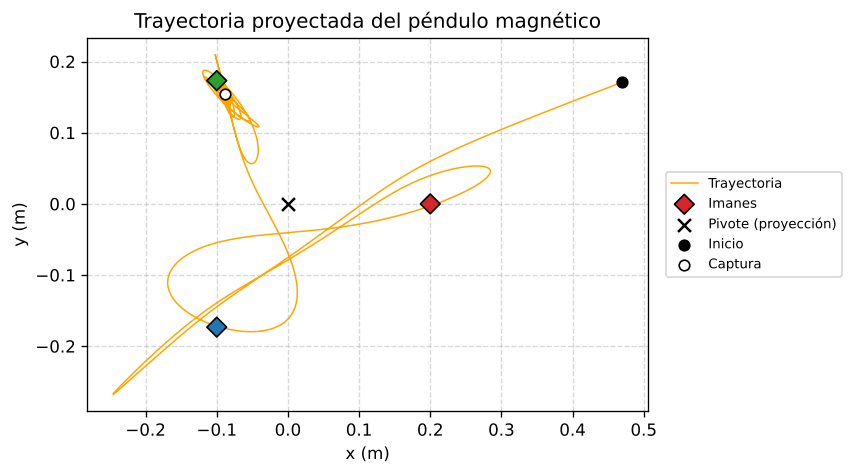

In [6]:
# =====================================================================
# FIGURA 1: TRAYECTORIA PROYECTADA DEL PÉNDULO
# =====================================================================
fig1, ax1 = plt.subplots(figsize=(7, 6), dpi=120, constrained_layout=True)

ax1.plot(trayectoria[:, 0], trayectoria[:, 1], color="orange", linewidth=0.9,
         label="Trayectoria")
ax1.scatter(imanes_xy[:, 0], imanes_xy[:, 1], c=COLORES_IMANES, s=70, marker="D",
            edgecolors="black", label="Imanes", zorder=5)
ax1.scatter(0, 0, c="black", marker="x", s=60, label="Pivote (proyección)", zorder=6)
ax1.scatter(*trayectoria[0], c="black", marker="o", s=40, label="Inicio", zorder=6)
ax1.scatter(*trayectoria[-1], c="white", edgecolors="black", marker="o", s=40,
            label="Captura", zorder=6)

ax1.set_xlabel("x (m)")
ax1.set_ylabel("y (m)")
ax1.set_title("Trayectoria proyectada del péndulo magnético")
ax1.set_aspect("equal")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=8)
plt.show()

**Figura 1.** Proyección horizontal de la trayectoria de referencia hasta su captura. Los rombos indican la posición de los imanes (con el color que los identifica en las figuras siguientes) y la cruz, la proyección del pivote.

### Paisaje de energía potencial

Los puntos de equilibrio estable del péndulo son los mínimos de la energía potencial $U$ sobre la esfera. Se calcula $U$ en una malla de proyecciones horizontales y se localizan sus mínimos con un método de optimización local que parte de la posición de cada imán (Virtanen et al., 2020).

Mínimos de U (posiciones de equilibrio estable):
  imán 0: (+0.1769, -0.0000) m, distancia al eje = 0.1769 m, U = -1.3896 J
  imán 1: (-0.0885, +0.1532) m, distancia al eje = 0.1769 m, U = -1.3896 J
  imán 2: (-0.0885, -0.1532) m, distancia al eje = 0.1769 m, U = -1.3896 J
U en el centro (0, 0): -0.9647 J


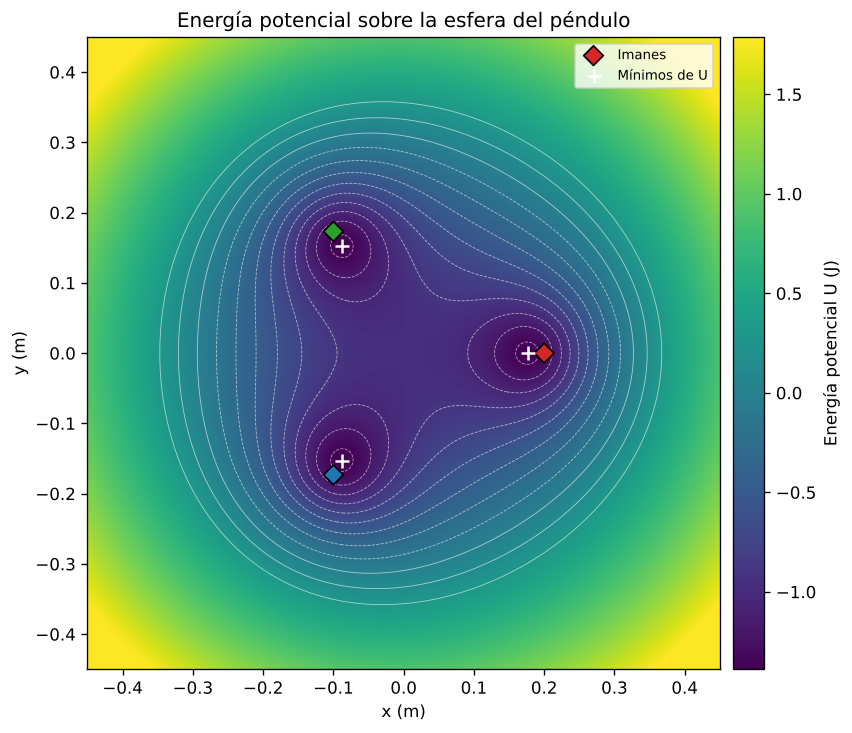

In [7]:
# =====================================================================
# MÍNIMOS DE LA ENERGÍA POTENCIAL Y FIGURA 2
# =====================================================================
minimos = []
for xi, yi in imanes_xy:
    resultado = minimize(lambda p: energia_potencial(p[0], p[1]), x0=[xi, yi],
                         method="Nelder-Mead", options={"xatol": 1e-8, "fatol": 1e-12})
    minimos.append(resultado.x)
minimos = np.array(minimos)

print("Mínimos de U (posiciones de equilibrio estable):")
for k, (xm, ym) in enumerate(minimos):
    print(f"  imán {k}: ({xm:+.4f}, {ym:+.4f}) m, distancia al eje = {np.hypot(xm, ym):.4f} m, "
          f"U = {energia_potencial(xm, ym):.4f} J")
print(f"U en el centro (0, 0): {energia_potencial(0.0, 0.0):.4f} J")

malla = np.linspace(-0.45, 0.45, 361)
Xu, Yu = np.meshgrid(malla, malla)
Uu = energia_potencial(Xu, Yu)

fig2, ax2 = plt.subplots(figsize=(7, 6), dpi=120, constrained_layout=True)
im = ax2.imshow(Uu, extent=[malla[0], malla[-1], malla[0], malla[-1]], origin="lower",
                cmap="viridis", vmax=np.percentile(Uu, 98))
ax2.contour(Xu, Yu, Uu, levels=np.linspace(-1.35, 0.3, 12), colors="white",
            linewidths=0.5, alpha=0.6)
ax2.scatter(imanes_xy[:, 0], imanes_xy[:, 1], c=COLORES_IMANES, s=70, marker="D",
            edgecolors="black", label="Imanes", zorder=5)
ax2.scatter(minimos[:, 0], minimos[:, 1], c="white", marker="+", s=80,
            label="Mínimos de U", zorder=6)
cbar = fig2.colorbar(im, ax=ax2, pad=0.02)
cbar.set_label("Energía potencial U (J)")
ax2.set_xlabel("x (m)")
ax2.set_ylabel("y (m)")
ax2.set_title("Energía potencial sobre la esfera del péndulo")
ax2.legend(loc="upper right", fontsize=8)
plt.show()

**Figura 2.** Energía potencial (gravitatoria más magnética) de la masa sobre la esfera, en función de su proyección horizontal. Las líneas blancas son curvas de nivel y las cruces, los mínimos de $U$, que corresponden a las tres posiciones de equilibrio estable.

### Cuencas de atracción

Para cada punto de una malla de $200 \times 200$ proyecciones horizontales se suelta la masa desde el reposo y se registra el imán de captura. El conjunto de condiciones iniciales que terminan en un mismo imán es su cuenca de atracción. Para examinar la estructura de las fronteras a escalas menores, se calcula también una ampliación de una región del mapa con la misma resolución.

Mapa de 40000 condiciones iniciales calculado en 17.1 s
Trayectorias sin capturar antes de 60 s: 0
  fracción de condiciones iniciales capturadas por el imán 0: 0.319
  fracción de condiciones iniciales capturadas por el imán 1: 0.341
  fracción de condiciones iniciales capturadas por el imán 2: 0.341
Tiempo de captura: mediana 15.7 s, máximo 20.4 s


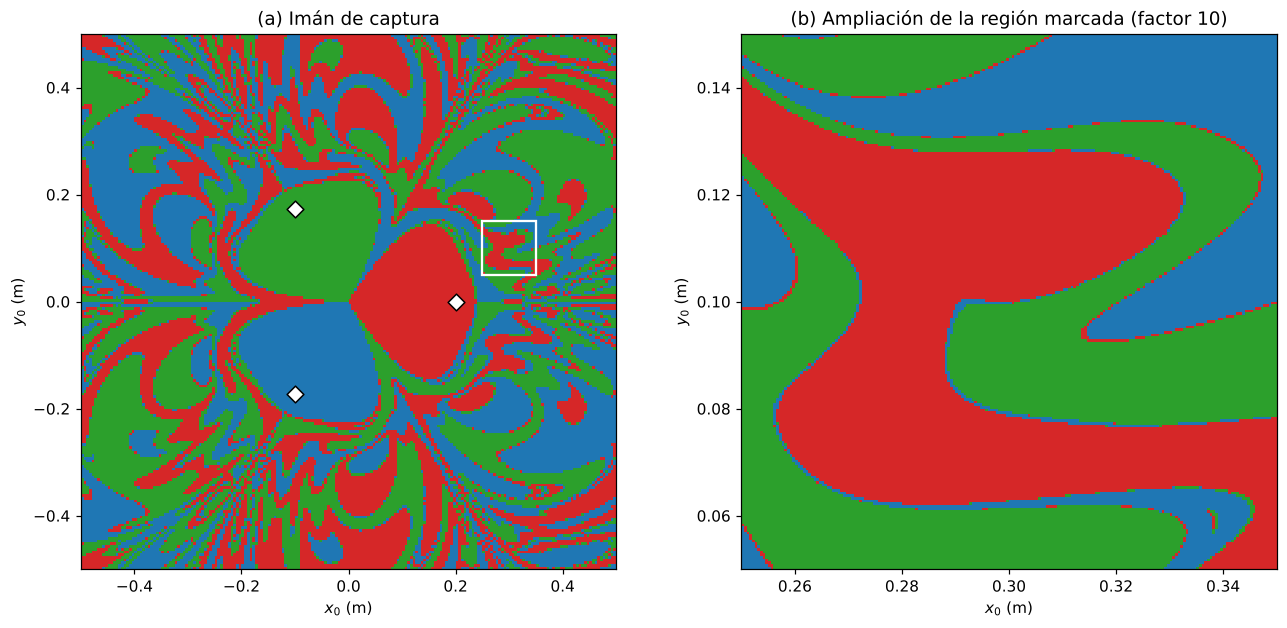

In [8]:
# =====================================================================
# MAPA DE CUENCAS DE ATRACCIÓN (FIGURA 3)
# =====================================================================
N_MALLA = 200
lado = np.linspace(-0.5, 0.5, N_MALLA)
X0, Y0 = np.meshgrid(lado, lado)

inicio = time.time()
iman_mapa, t_mapa = integrar(X0.ravel(), Y0.ravel())
iman_mapa = iman_mapa.reshape(X0.shape)
t_mapa = t_mapa.reshape(X0.shape)
print(f"Mapa de {iman_mapa.size} condiciones iniciales calculado en {time.time() - inicio:.1f} s")
print(f"Trayectorias sin capturar antes de {T_MAX:.0f} s: {np.sum(iman_mapa < 0)}")
for k in range(3):
    print(f"  fracción de condiciones iniciales capturadas por el imán {k}: {np.mean(iman_mapa == k):.3f}")
print(f"Tiempo de captura: mediana {np.nanmedian(t_mapa):.1f} s, máximo {np.nanmax(t_mapa):.1f} s")

# Ampliación de una región de la frontera, con la misma resolución de la malla
ZOOM = (0.25, 0.35, 0.05, 0.15)   # (x_min, x_max, y_min, y_max) en metros
lado_zx = np.linspace(ZOOM[0], ZOOM[1], N_MALLA)
lado_zy = np.linspace(ZOOM[2], ZOOM[3], N_MALLA)
Xz, Yz = np.meshgrid(lado_zx, lado_zy)
iman_zoom, _ = integrar(Xz.ravel(), Yz.ravel())
iman_zoom = iman_zoom.reshape(Xz.shape)

colores_cuencas = ListedColormap(COLORES_IMANES)
fig3, (ax3a, ax3b) = plt.subplots(1, 2, figsize=(12, 5.6), dpi=110, constrained_layout=True)

ax3a.imshow(iman_mapa, extent=[lado[0], lado[-1], lado[0], lado[-1]], origin="lower",
            interpolation="nearest", cmap=colores_cuencas, vmin=-0.5, vmax=2.5)
ax3a.scatter(imanes_xy[:, 0], imanes_xy[:, 1], c="white", s=60, marker="D", edgecolors="black")
ax3a.add_patch(plt.Rectangle((ZOOM[0], ZOOM[2]), ZOOM[1] - ZOOM[0], ZOOM[3] - ZOOM[2],
                             fill=False, edgecolor="white", linewidth=1.5))
ax3a.set_title("(a) Imán de captura")
ax3a.set_xlabel("$x_0$ (m)")
ax3a.set_ylabel("$y_0$ (m)")

ax3b.imshow(iman_zoom, extent=list(ZOOM), origin="lower", interpolation="nearest",
            cmap=colores_cuencas, vmin=-0.5, vmax=2.5)
ax3b.set_title("(b) Ampliación de la región marcada (factor 10)")
ax3b.set_xlabel("$x_0$ (m)")
ax3b.set_ylabel("$y_0$ (m)")
plt.show()

**Figura 3.** (a) Cuencas de atracción: cada punto representa la proyección horizontal desde la que se suelta la masa en reposo, coloreado según el imán que la captura (los colores son los de los imanes en la Figura 1). (b) Ampliación de la región enmarcada en (a), calculada con la misma resolución de malla.

#### Robustez frente al paso de tiempo

Antes de interpretar la estructura fina del mapa conviene comprobar que no es un artefacto numérico. Para ello se repite el cálculo en una malla de $100 \times 100$ con el paso de tiempo $\Delta t$ y con $\Delta t/2$, y se cuenta en qué fracción de las condiciones iniciales coincide el imán de captura.

In [9]:
# =====================================================================
# COMPARACIÓN DEL MAPA CON PASOS DE TIEMPO dt Y dt/2
# =====================================================================
lado_c = np.linspace(-0.5, 0.5, 100)
Xc, Yc = np.meshgrid(lado_c, lado_c)

inicio = time.time()
iman_dt, _ = integrar(Xc.ravel(), Yc.ravel(), dt=dt)
iman_dt2, _ = integrar(Xc.ravel(), Yc.ravel(), dt=dt / 2, cada=100)
print(f"Comparación calculada en {time.time() - inicio:.1f} s")
print(f"Fracción de condiciones iniciales con el mismo imán de captura "
      f"(dt = {dt*1e3:.0f} ms frente a dt = {dt*1e3/2:.0f} ms): {np.mean(iman_dt == iman_dt2):.4f}")

# Ubicación de las discrepancias: dentro o fuera del círculo de los imanes
distinto = iman_dt != iman_dt2
radio = np.hypot(Xc.ravel(), Yc.ravel())
print(f"Condiciones iniciales con distinto imán de captura: {distinto.sum()} "
      f"({np.sum(distinto & (radio < R_IMANES))} de ellas a menos de {R_IMANES} m del eje)")

Comparación calculada en 12.6 s
Fracción de condiciones iniciales con el mismo imán de captura (dt = 2 ms frente a dt = 1 ms): 0.9796
Condiciones iniciales con distinto imán de captura: 204 (0 de ellas a menos de 0.2 m del eje)


### Sensibilidad del estado final a la condición inicial

Una forma cuantitativa de medir la sensibilidad del estado final es la fracción de condiciones iniciales inciertas (Grebogi et al., 1983): se toma un conjunto de condiciones iniciales al azar, se desplaza cada una una distancia $\varepsilon$ en una dirección aleatoria y se cuenta la fracción $f(\varepsilon)$ de casos en los que cambia el imán de captura. Si la frontera entre cuencas fuera una curva suave, $f$ sería proporcional a $\varepsilon$; una frontera de estructura fractal produce en cambio una ley de potencias $f(\varepsilon) \propto \varepsilon^{\alpha}$ con $\alpha < 1$, y la dimensión de la frontera en el plano de condiciones iniciales es $D = 2 - \alpha$.

Cálculo completado en 8.0 s
  epsilon = 1e-02 m:  f = 0.3037 +/- 0.0084
  epsilon = 3e-03 m:  f = 0.1467 +/- 0.0065
  epsilon = 1e-03 m:  f = 0.0647 +/- 0.0045
  epsilon = 3e-04 m:  f = 0.0223 +/- 0.0027
Exponente de incertidumbre (ajuste global): alpha = 0.74;  dimensión efectiva de la frontera D = 1.26
  pendiente local entre 1e-02 y 3e-03 m: alpha = 0.60
  pendiente local entre 3e-03 y 1e-03 m: alpha = 0.75
  pendiente local entre 1e-03 y 3e-04 m: alpha = 0.88


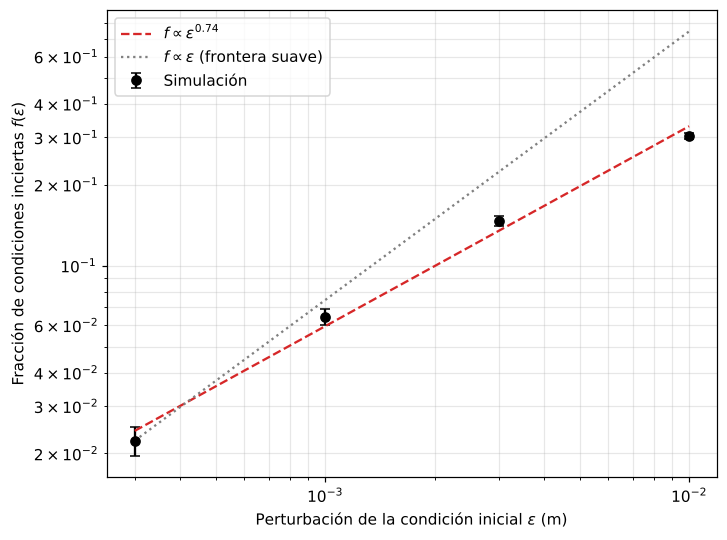

In [10]:
# =====================================================================
# FRACCIÓN DE CONDICIONES INICIALES INCIERTAS (FIGURA 4)
# =====================================================================
generador = np.random.default_rng(2024)
N_MUESTRA = 3000
x_base = generador.uniform(-0.5, 0.5, N_MUESTRA)
y_base = generador.uniform(-0.5, 0.5, N_MUESTRA)

inicio = time.time()
iman_base, _ = integrar(x_base, y_base)

epsilons = np.array([1e-2, 3e-3, 1e-3, 3e-4])
fracciones = []
desplazadas = {}
for eps in epsilons:
    direccion = generador.uniform(0.0, 2.0 * np.pi, N_MUESTRA)
    x_eps = x_base + eps * np.cos(direccion)
    y_eps = y_base + eps * np.sin(direccion)
    iman_eps, _ = integrar(x_eps, y_eps)
    fracciones.append(np.mean(iman_eps != iman_base))
    desplazadas[eps] = (x_eps, y_eps, iman_eps)
fracciones = np.array(fracciones)
print(f"Cálculo completado en {time.time() - inicio:.1f} s")

# Incertidumbre estadística de cada fracción (distribución binomial)
error_f = np.sqrt(fracciones * (1 - fracciones) / N_MUESTRA)

alpha, log_c = np.polyfit(np.log10(epsilons), np.log10(fracciones), 1)
for eps, f, ef in zip(epsilons, fracciones, error_f):
    print(f"  epsilon = {eps:.0e} m:  f = {f:.4f} +/- {ef:.4f}")
print(f"Exponente de incertidumbre (ajuste global): alpha = {alpha:.2f};  "
      f"dimensión efectiva de la frontera D = {2 - alpha:.2f}")

# Pendiente local entre valores consecutivos de epsilon
alpha_local = np.diff(np.log(fracciones)) / np.diff(np.log(epsilons))
for (e1, e2), a in zip(zip(epsilons[:-1], epsilons[1:]), alpha_local):
    print(f"  pendiente local entre {e1:.0e} y {e2:.0e} m: alpha = {a:.2f}")

fig4, ax4 = plt.subplots(figsize=(6.5, 4.8), dpi=110, constrained_layout=True)
ax4.errorbar(epsilons, fracciones, yerr=error_f, fmt="o", color="black", capsize=3,
             label="Simulación")
ax4.set_xscale("log")
ax4.set_yscale("log")
eps_linea = np.logspace(np.log10(epsilons.min()), np.log10(epsilons.max()), 50)
ax4.loglog(eps_linea, 10**log_c * eps_linea**alpha, "--", color="tab:red",
           label=rf"$f \propto \varepsilon^{{{alpha:.2f}}}$")
ax4.loglog(eps_linea, fracciones[-1] * eps_linea / epsilons[-1], ":", color="gray",
           label=r"$f \propto \varepsilon$ (frontera suave)")
ax4.set_xlabel(r"Perturbación de la condición inicial $\varepsilon$ (m)")
ax4.set_ylabel(r"Fracción de condiciones inciertas $f(\varepsilon)$")
ax4.grid(True, which="both", alpha=0.3)
ax4.legend()
plt.show()

**Figura 4.** Fracción de condiciones iniciales cuyo imán de captura cambia al desplazarlas una distancia $\varepsilon$, junto con el ajuste por ley de potencias y, como referencia, la dependencia lineal que produciría una frontera suave.

Condición A: (+0.1817, +0.1335) m -> imán 2
Condición B: (+0.1822, +0.1327) m -> imán 0
Separación inicial: 1.00 mm


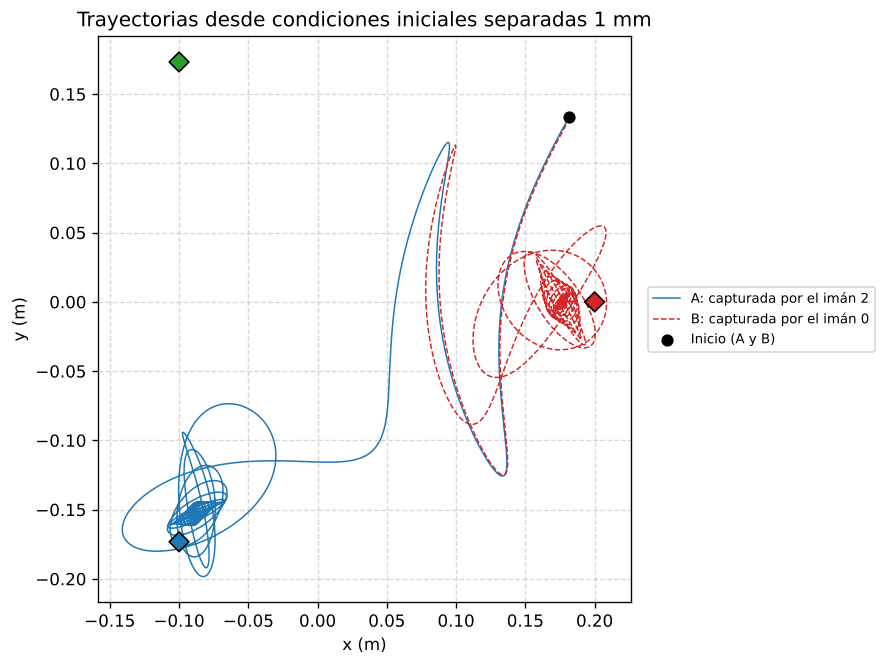

In [11]:
# =====================================================================
# DOS CONDICIONES INICIALES SEPARADAS 1 mm (FIGURA 5)
# =====================================================================
# Entre las parejas separadas 1 mm cuyo imán de captura difiere, se toma la
# primera de la muestra para ilustrar la divergencia de las trayectorias.
x_eps, y_eps, iman_eps = desplazadas[1e-3]
j = np.flatnonzero(iman_eps != iman_base)[0]

_, _, tray_a = integrar(x_base[j], y_base[j], registrar=True)
_, _, tray_b = integrar(x_eps[j], y_eps[j], registrar=True)
separacion = np.hypot(x_eps[j] - x_base[j], y_eps[j] - y_base[j])
print(f"Condición A: ({x_base[j]:+.4f}, {y_base[j]:+.4f}) m -> imán {iman_base[j]}")
print(f"Condición B: ({x_eps[j]:+.4f}, {y_eps[j]:+.4f}) m -> imán {iman_eps[j]}")
print(f"Separación inicial: {separacion * 1e3:.2f} mm")

fig5, ax5 = plt.subplots(figsize=(7, 6), dpi=120, constrained_layout=True)
ax5.plot(tray_a[:, 0], tray_a[:, 1], color=COLORES_IMANES[iman_base[j]], linewidth=0.9,
         label=f"A: capturada por el imán {iman_base[j]}")
ax5.plot(tray_b[:, 0], tray_b[:, 1], color=COLORES_IMANES[iman_eps[j]], linewidth=0.9,
         linestyle="--", label=f"B: capturada por el imán {iman_eps[j]}")
ax5.scatter(imanes_xy[:, 0], imanes_xy[:, 1], c=COLORES_IMANES, s=70, marker="D",
            edgecolors="black", zorder=5)
ax5.scatter(x_base[j], y_base[j], c="black", s=40, zorder=6, label="Inicio (A y B)")
ax5.set_xlabel("x (m)")
ax5.set_ylabel("y (m)")
ax5.set_title("Trayectorias desde condiciones iniciales separadas 1 mm")
ax5.set_aspect("equal")
ax5.grid(True, linestyle="--", alpha=0.5)
ax5.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=8)
plt.show()

**Figura 5.** Trayectorias que parten del reposo desde dos posiciones separadas 1 mm y terminan capturadas por imanes distintos.

# Resultados, análisis y conclusiones

## Resultados

**Trayectoria de referencia (Figura 1).** La masa, soltada desde el reposo con $\theta_0 = 30^\circ$ y $\phi_0 = 20^\circ$, atraviesa la región de los imanes pasando cerca del imán rojo y del azul, describe varios lazos amplios (uno de ellos alrededor del imán rojo) y termina atrapada por el imán verde, alrededor del cual oscila con amplitud decreciente hasta quedar en reposo a los 15.9 s. Cada paso sobre un imán desvía bruscamente la trayectoria, y la sucesión de esos encuentros, más que la oscilación pendular, es lo que decide el destino final.

**Paisaje de energía potencial (Figura 2).** La energía potencial tiene tres pozos, uno junto a cada imán. Sus mínimos están a 0.177 m del eje, es decir, desplazados unos 2.3 cm hacia el centro respecto de los imanes, porque allí la componente tangencial de la gravedad equilibra la atracción magnética. El centro $(0, 0)$ es también un punto de equilibrio, por simetría, pero inestable: su energía ($-0.965$ J) supera en 0.42 J la de los mínimos ($-1.390$ J). Por eso el péndulo no puede quedar en reposo bajo el pivote y cada trayectoria termina en uno de los tres pozos.

**Cuencas de atracción (Figura 3).** Las 40 000 trayectorias del mapa terminan capturadas antes de 60 s (la mediana del tiempo de captura es 15.7 s y el máximo, 20.4 s), y cada imán recibe cerca de un tercio de las condiciones iniciales (0.319, 0.341 y 0.341). Cerca del eje, cada imán tiene una cuenca compacta: un lóbulo que lo contiene y que se extiende hasta el centro, donde los tres lóbulos se tocan. Fuera del círculo de los imanes el mapa cambia por completo: las cuencas forman franjas curvas entrelazadas, y entre dos franjas de colores distintos aparecen con frecuencia franjas delgadas del tercer color. La ampliación de la Figura 3b muestra que esa alternancia persiste a una escala diez veces menor, aunque con fronteras más suaves.

**Robustez numérica.** Al reducir el paso de tiempo de 2 ms a 1 ms, el 97.96 % de las condiciones iniciales de la malla de comprobación conserva su imán de captura. Las discrepancias aparecen solo en la región exterior de franjas entrelazadas, donde casi todos los puntos de la malla son vecinos de otra cuenca; los lóbulos centrales no cambian. La estructura descrita no es, por tanto, un artefacto del integrador.

**Sensibilidad del estado final (Figuras 4 y 5).** La fracción de condiciones iniciales cuyo imán de captura cambia al desplazarlas una distancia $\varepsilon$ pasa de 0.304 para $\varepsilon = 1$ cm a 0.022 para $\varepsilon = 0.3$ mm. Un ajuste global da $f(\varepsilon) \propto \varepsilon^{0.74}$, de modo que reducir diez veces la incertidumbre de la condición inicial (de 3 mm a 0.3 mm) solo reduce unas siete veces la fracción de resultados inciertos. La pendiente local, sin embargo, no es constante: crece de 0.60 a 0.88 al disminuir $\varepsilon$. La Figura 5 lo ilustra con dos condiciones iniciales separadas 1 mm: las trayectorias son indistinguibles durante el primer recorrido, se separan tras pasar cerca del imán rojo y terminan en imanes distintos.

## Análisis

El mecanismo de la sensibilidad es el mismo que describió Lorenz (1963) para sistemas caóticos: cada paso cerca de un imán actúa como una dispersión fuerte que amplifica las diferencias entre trayectorias vecinas, y tras unos pocos pasos una diferencia de 1 mm en la posición inicial basta para cambiar el imán sobre el que la masa pierde finalmente su energía. A diferencia de los sistemas forzados, aquí la dinámica irregular es transitoria: la fricción disipa energía en cada recorrido y, cuando la energía ya no alcanza para remontar la región central, la masa queda confinada en un pozo. Por eso los lóbulos centrales del mapa son regulares (desde ellos la masa desciende directamente al pozo más cercano y, al disipar energía, ya no puede remontar la región central hacia otro imán), mientras que las condiciones iniciales más alejadas del eje, con más energía, dan lugar a las franjas entrelazadas.

El exponente $\alpha < 1$ indica que, en el rango de escalas explorado, las fronteras entre cuencas tienen una dimensión efectiva $D = 2 - \alpha$ mayor que 1 (entre 1.4 y 1.1 según la escala), propia de una estructura de tipo fractal. El aumento de la pendiente local hacia escalas pequeñas coincide con lo que Motter et al. (2013) describieron como caos doblemente transitorio: en sistemas disipativos sin forzamiento, la estructura que separa las cuencas solo existe mientras la energía es alta, de modo que las fronteras se simplifican al ampliarlas y su dimensión efectiva tiende a 1 a escalas suficientemente pequeñas. La ampliación de la Figura 3b, con fronteras más suaves que las del mapa completo, es la manifestación visual del mismo fenómeno.

El coeficiente de fricción controla el carácter de la solución: con $b$ alto la energía se disipa rápido, la masa recorre pocas órbitas y las cuencas son más simples; con $b$ bajo la masa visita los imanes muchas más veces antes de quedar atrapada, las franjas se vuelven más finas y la región de condiciones iniciales inciertas crece. El valor $b = 0.7$ kg/s usado aquí es un compromiso entre una dinámica suficientemente rica y un mapa de cuencas que no dependa del paso de tiempo, como se verificó.

## Conclusiones

1. Con los imanes situados justo por debajo del punto más bajo del péndulo, la energía potencial tiene tres pozos junto a los imanes y un equilibrio inestable en el centro; toda trayectoria termina en reposo en uno de los tres pozos.
2. El imán de captura depende de manera muy sensible de la condición inicial fuera de la región central: las cuencas de atracción forman franjas entrelazadas, y dos posiciones de partida separadas 1 mm pueden terminar en imanes distintos.
3. La fracción de condiciones iniciales inciertas escala como $f(\varepsilon) \propto \varepsilon^{\alpha}$ con $\alpha \approx 0.6$-$0.9$ en el rango de 0.3 mm a 1 cm, con una pendiente que crece hacia escalas pequeñas, como corresponde al caos doblemente transitorio de los sistemas disipativos sin forzamiento (Motter et al., 2013).
4. El integrador de Euler-Cromer con restricción geométrica explícita (Cromer, 1981) es suficiente para estos resultados: el mapa de cuencas cambia en menos del 2.1 % de los puntos al reducir el paso de tiempo a la mitad. Un análisis cuantitativo más fino de las fronteras, a escalas menores que las exploradas, requeriría un integrador de mayor orden o un paso de tiempo más pequeño (Strogatz, 2024).

## Trabajo futuro

- **Barrido en la fricción.** Repetir el mapa de cuencas y la medida de $f(\varepsilon)$ para varios valores de $b$, para cuantificar cómo crece la región de condiciones iniciales inciertas al disminuir la disipación.
- **Ley de fuerza dipolar.** Sustituir la atracción de tipo inverso al cuadrado por la interacción entre dipolos magnéticos, más cercana a la de dos imanes permanentes, y comparar las cuencas resultantes.
- **Integradores de mayor orden.** Implementar Runge-Kutta de cuarto orden (RK4) o un esquema de paso adaptativo y estimar exponentes de Lyapunov de tiempo finito a lo largo de las trayectorias.
- **Animaciones.** Generar animaciones de trayectorias individuales o de conjuntos de trayectorias, útiles para presentaciones.

## Referencias

### Fundamentos teóricos y numéricos

Cromer, A. (1981). Stable solutions using the Euler approximation. *American Journal of Physics*, *49*(5), 455-459. https://doi.org/10.1119/1.12478

Grebogi, C., McDonald, S. W., Ott, E., & Yorke, J. A. (1983). Final state sensitivity: An obstruction to predictability. *Physics Letters A*, *99*(9), 415-418. https://doi.org/10.1016/0375-9601(83)90945-3

Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., Wieser, E., Taylor, J., Berg, S., Smith, N. J., Kern, R., Picus, M., Hoyer, S., van Kerkwijk, M. H., Brett, M., Haldane, A., del Río, J. F., Wiebe, M., Peterson, P., … Oliphant, T. E. (2020). Array programming with NumPy. *Nature*, *585*(7825), 357-362. https://doi.org/10.1038/s41586-020-2649-2

Lorenz, E. N. (1963). Deterministic nonperiodic flow. *Journal of the Atmospheric Sciences*, *20*(2), 130-141. https://doi.org/10.1175/1520-0469(1963)020<0130:DNF>2.0.CO;2

Motter, A. E., Gruiz, M., Károlyi, G., & Tél, T. (2013). Doubly transient chaos: Generic form of chaos in autonomous dissipative systems. *Physical Review Letters*, *111*(19), 194101. https://doi.org/10.1103/PhysRevLett.111.194101

Strogatz, S. H. (2024). *Nonlinear dynamics and chaos: With applications to physics, biology, chemistry, and engineering* (3.ª ed.). CRC Press.

Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., Burovski, E., Peterson, P., Weckesser, W., Bright, J., van der Walt, S. J., Brett, M., Wilson, J., Millman, K. J., Mayorov, N., Nelson, A. R. J., Jones, E., Kern, R., Larson, E., … van Mulbregt, P. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods*, *17*(3), 261-272. https://doi.org/10.1038/s41592-019-0686-2

### Recursos complementarios

Berg, I. (Beltoforion). (s. f.). *The magnetic pendulum: Hands-on chaos theory*. beltoforion.de. Recuperado el 19 de septiembre de 2026, de https://beltoforion.de/en/magnetic-pendulum

Nylander, P. (s. f.). *Fractals*. Recuperado de http://www.bugman123.com/Fractals/index.html

Muller, D. [Veritasium]. (2019, 6 de diciembre). *Chaos: The science of the butterfly effect* [Video]. YouTube. https://www.youtube.com/watch?v=fDek6cYijxI

MIT OpenCourseWare. (2016). *Lorenz attractor and chaos* [Video]. YouTube. https://www.youtube.com/watch?v=Q_f1vRLAENA